# Dataset analysis

Run these cells to summarize what is in the current training and finetuning data: source sizes, labels, mechanism classes, duplicate fingerprints, and fingerprint feature families.


In [1]:
import json
import os
import pickle
import sys
from collections import Counter

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from shared.ml_helper import make_fingerprint
from shared.fingerprint_schema import build_feature_entries, build_section_layout, fingerprint_size, build_feature_map


In [12]:
dataset_dirs = [
    ("base", "training_sets/20260202"),
    ("finetuning", "finetuning"),
]

mechanism_type_names = {
    0: "atom to atom",
    1: "atom to bond",
    2: "bond to atom",
    3: "bond to bond",
    4: "atom to H+",
    5: "bond to H+",
    6: "H- to atom",
    7: "H- to bond",
    8: "E2 elimination",
    9: "E1 elimination",
    10: "carbocation formation",
}

expected_fingerprint_size = fingerprint_size()
print(f"Expected fingerprint width: {expected_fingerprint_size}")


Expected fingerprint width: 182


In [13]:
def natural_sort_key(value):
    text = str(value)
    return (not text.isdigit(), int(text) if text.isdigit() else text)


def load_mechanism_records(dataset_name, dataset_dir):
    records = []
    skipped = Counter()

    if not os.path.isdir(dataset_dir):
        print(f"Skipping missing directory: {dataset_dir}")
        return records, skipped

    subdirs = [d for d in os.listdir(dataset_dir) if os.path.isdir(os.path.join(dataset_dir, d))]
    for subdir in sorted(subdirs, key=natural_sort_key):
        folder_path = os.path.join(dataset_dir, subdir)
        json_path = os.path.join(folder_path, 'data.json')
        pkl_path = os.path.join(folder_path, 'sm.pkl')

        if not os.path.exists(json_path) or not os.path.exists(pkl_path):
            skipped['missing_files'] += 1
            continue

        try:
            with open(pkl_path, 'rb') as f:
                sm = pickle.load(f)
            with open(json_path, 'r') as f:
                data = json.load(f)
        except Exception as e:
            skipped[f'load_error: {type(e).__name__}'] += 1
            continue

        contributor = data.get('contributor') or None
        for choice_id, info in data.get('choices', {}).items():
            outcome = info.get('probable')
            mechanism = info.get('mechanism')
            if outcome is None:
                skipped['unlabeled_choice'] += 1
                continue
            if not mechanism:
                skipped['missing_mechanism'] += 1
                continue

            try:
                fingerprint = make_fingerprint(sm, mechanism)
            except Exception as e:
                skipped[f'fingerprint_error: {type(e).__name__}'] += 1
                continue

            records.append({
                'source': dataset_name,
                'dataset_dir': dataset_dir,
                'folder': subdir,
                'choice_id': choice_id,
                'contributor': contributor,
                'probable': int(outcome),
                'mechanism': mechanism,
                'mechanism_type': mechanism[0],
                'mechanism_type_name': mechanism_type_names.get(mechanism[0], f"unknown={mechanism[0]}"),
                'fingerprint': fingerprint,
            })

    return records, skipped


In [14]:
all_records = []
skip_summary = {}
for dataset_name, dataset_dir in dataset_dirs:
    records, skipped = load_mechanism_records(dataset_name, dataset_dir)
    all_records.extend(records)
    skip_summary[dataset_name] = skipped

records_df = pd.DataFrame(all_records)
if records_df.empty:
    raise ValueError("No labeled mechanism records found. Check dataset_dirs.")

fingerprints = np.asarray(records_df['fingerprint'].tolist(), dtype=float)
if fingerprints.shape[1] != expected_fingerprint_size:
    raise ValueError(f"Fingerprint width mismatch: got {fingerprints.shape[1]}, expected {expected_fingerprint_size}")

print(f"Loaded {len(records_df):,} labeled mechanism examples")
display(records_df[['source', 'folder', 'choice_id', 'probable', 'mechanism_type_name', 'contributor']].head())
print("Skipped choices/files:")
for source, skipped in skip_summary.items():
    print(source, dict(skipped))


Loaded 9,445 labeled mechanism examples


,source,folder,choice_id,probable,mechanism_type_name,contributor
0,base,1,0,1,atom to atom,Richard
1,base,1,1,1,E1 elimination,Richard
2,base,2,0,0,E1 elimination,Richard
3,base,2,1,1,atom to atom,Richard
4,base,2,2,0,E1 elimination,Richard


Skipped choices/files:
base {'unlabeled_choice': 132}
finetuning {'unlabeled_choice': 6121, 'fingerprint_error: IndexError': 2}


In [11]:
new_df = records_df[records_df['mechanism_type_name'].isin(['E1 elimination', 'E2 elimination'])]
new_df.to_csv('elimination_records.csv', index=False)

In [15]:
source_summary = (
    records_df.groupby('source')
    .agg(
        examples=('probable', 'size'),
        positives=('probable', 'sum'),
        unique_folders=('folder', 'nunique'),
        contributors=('contributor', 'nunique'),
    )
)
source_summary['negatives'] = source_summary['examples'] - source_summary['positives']
source_summary['positive_rate'] = source_summary['positives'] / source_summary['examples']
display(source_summary)

label_summary = pd.crosstab(records_df['source'], records_df['probable'], margins=True)
label_summary = label_summary.rename(columns={0: 'negative', 1: 'positive'})
display(label_summary)

mechanism_summary = pd.crosstab(
    records_df['mechanism_type_name'],
    records_df['probable'],
    margins=True,
).rename(columns={0: 'negative', 1: 'positive'}).sort_values('All', ascending=False)
display(mechanism_summary)


,examples,positives,unique_folders,contributors,negatives,positive_rate
source,,,,,,
base,9355,1409,396,1,7946,0.150615
finetuning,90,33,46,13,57,0.366667


probable,negative,positive,All
source,,,
base,7946,1409,9355
finetuning,57,33,90
All,8003,1442,9445


probable,negative,positive,All
mechanism_type_name,,,
All,8003,1442,9445
E2 elimination,2936,176,3112
atom to bond,2505,503,3008
bond to bond,1191,90,1281
atom to H+,434,342,776
carbocation formation,269,53,322
atom to atom,128,159,287
bond to H+,230,29,259
E1 elimination,199,50,249


In [16]:
def stable_fingerprint_key(row):
    return tuple('nan' if pd.isna(value) else int(value) for value in row)

fingerprint_keys = [stable_fingerprint_key(row) for row in fingerprints]
labeled_keys = [(key, int(outcome)) for key, outcome in zip(fingerprint_keys, records_df['probable'])]
records_df = records_df.assign(
    fingerprint_key=fingerprint_keys,
    labeled_fingerprint_key=labeled_keys,
)

duplicate_group_sizes = records_df.groupby('labeled_fingerprint_key').size()
duplicate_groups = duplicate_group_sizes[duplicate_group_sizes > 1]

print(f"Unique fingerprints: {records_df['fingerprint_key'].nunique():,}")
print(f"Unique labeled fingerprints: {records_df['labeled_fingerprint_key'].nunique():,}")
print(f"Duplicate labeled-fingerprint groups: {len(duplicate_groups):,}")
print(f"Rows inside duplicate labeled-fingerprint groups: {int(duplicate_groups.sum()):,}")

cross_source_duplicates = (
    records_df.groupby('labeled_fingerprint_key')['source']
    .nunique()
    .loc[lambda s: s > 1]
)
print(f"Duplicate labeled fingerprints appearing in multiple sources: {len(cross_source_duplicates):,}")

if len(duplicate_groups):
    dup_examples = (
        records_df[records_df['labeled_fingerprint_key'].isin(duplicate_groups.index)]
        .groupby(['mechanism_type_name', 'probable', 'source'])
        .size()
        .rename('rows')
        .reset_index()
        .sort_values('rows', ascending=False)
    )
    display(dup_examples.head(20))


Unique fingerprints: 6,258
Unique labeled fingerprints: 6,345
Duplicate labeled-fingerprint groups: 1,594
Rows inside duplicate labeled-fingerprint groups: 4,694
Duplicate labeled fingerprints appearing in multiple sources: 7


,mechanism_type_name,probable,source,rows
2,E2 elimination,0,base,1573
12,atom to bond,0,base,1168
20,bond to bond,0,base,476
6,atom to H+,0,base,295
8,atom to H+,1,base,224
0,E1 elimination,0,base,166
24,carbocation formation,0,base,162
14,atom to bond,1,base,156
16,bond to H+,0,base,100
11,atom to atom,1,base,74


NameError: name 'f_map' is not defined

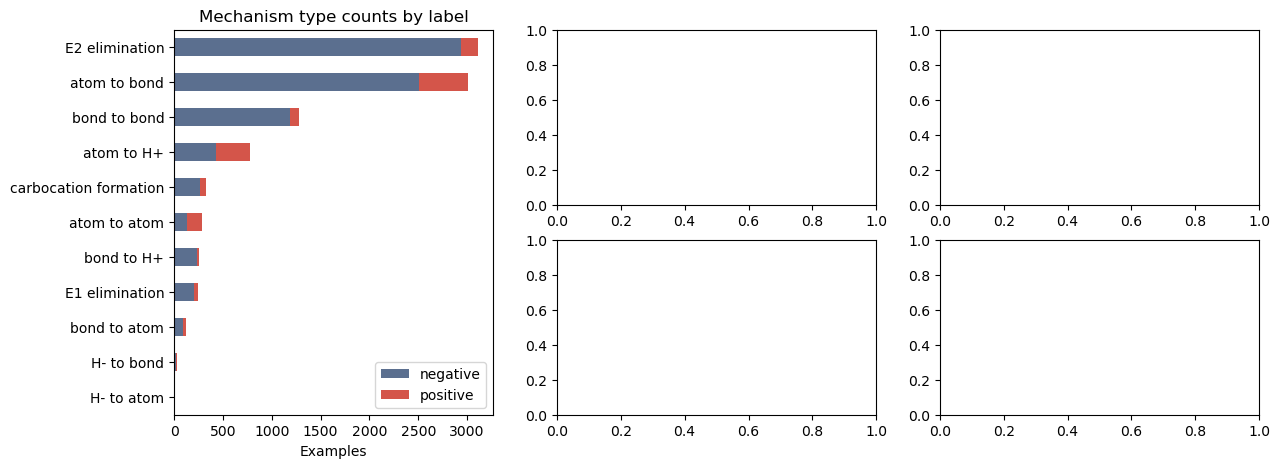

In [17]:

layout = [
    ['A', 'B', 'D'],
    ['A', 'C', 'E']
]

atom_colours = {
    'N': "#3050F8",
    'O': "#FF0D0D",
    'C': "#909090",
    'Cl':"#00FF00",
    'S': "#FFC832",
    'B':'#FFB5B5',
    'Al': "#BFA6A6",
    'P': '#FF8000',
    'F': '#90E050',
    'I': '#940094',
    'Br': '#A62929',
    'Si':'#F0C8A0',
    'Mg': '#8AFF00',
    'H_or_alkali': '#FFFFFF'
}

fig, axes = plt.subplot_mosaic(layout, figsize=(14, 5))

mechanism_by_label = pd.crosstab(
    records_df['mechanism_type_name'],
    records_df['probable'],
).rename(columns={0: 'negative', 1: 'positive'})
mechanism_by_label = mechanism_by_label.loc[mechanism_by_label.sum(axis=1).sort_values().index]
mechanism_by_label.plot(kind='barh', stacked=True, ax=axes['A'], color=['#5b6f8f', '#d4554a'])
axes['A'].set_title('Mechanism type counts by label')
axes['A'].set_xlabel('Examples')
axes['A'].set_ylabel('')
axes['A'].legend( loc="lower right")

from collections import Counter

atom_counter = []
atoms = [1,2,3,4]
for atom in atoms:
    atom_counter.append(Counter())

# Using .iterrows() allows you to access both the index and the full row data
for index, row in records_df[records_df["probable"] == 1].iterrows():
    record = row["fingerprint"]
    try:
        idx1 = record.index(1, 20, 35)
        atom_counter[0].update([f_map[idx1].split("=")[1]])       
    except ValueError:
        pass
    try:
        idx2 = record.index(1, 60, 75)
        atom_counter[1].update([f_map[idx2].split("=")[1]])      
    except ValueError:
        continue
    try:
        idx3 = record.index(1, 100, 115)
        atom_counter[2].update([f_map[idx3].split("=")[1]])      
    except ValueError:
        continue
    try:
        idx4 = record.index(1, 140, 155)
        atom_counter[3].update([f_map[idx4].split("=")[1]])      
    except ValueError:
        continue


mosaic = ['B', 'C', 'D', 'E']
for i, atom in enumerate(atom_counter):
    top5 = atom.most_common(5)
    other_size = sum(v for k, v in atom.items() if k not in dict(top5))

    labels = [k for k, _ in top5]
    sizes = [v for _, v in top5]

    if other_size:
        labels.append("Other")
        sizes.append(other_size)

    # 2. Generate the pie chart (coloured by atom_colours, default grey for unknown/Other)
    colors = [atom_colours.get(lbl, "#A7F2F5") for lbl in labels]
    _, label_texts = axes[mosaic[i]].pie(
        sizes,
        labels=labels,
        colors=colors,
    )


    # Loop through the percentage text objects and set their size
    # for autotext in autotexts:
    #     autotext.set_fontsize(8)
    #     #autotext.set_color('white')  # Optional: make them stand out!
    for label_text in label_texts:
        label_text.set_fontsize(10)
    axes[mosaic[i]].set_title(f"Atom {i+1}")

 



plt.tight_layout()
plt.show()


In [8]:
section_totals = (
    feature_summary.groupby('section')['observed_count']
    .sum()
    .reindex([section['section'] for section in build_section_layout()])
)

plt.figure(figsize=(10, 5))
section_totals.plot(kind='bar', color='#7b6d9c')
plt.title('Feature activations by fingerprint section')
plt.xlabel('Fingerprint section')
plt.ylabel('Total active bits')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


NameError: name 'feature_summary' is not defined

In [9]:
f_map = build_feature_map()

Counter({'O': 768,
         'N': 238,
         'C': 175,
         'Cl': 53,
         'Br': 34,
         'P': 21,
         'I': 17,
         'F': 17,
         'H_or_alkali': 15,
         'S': 9})

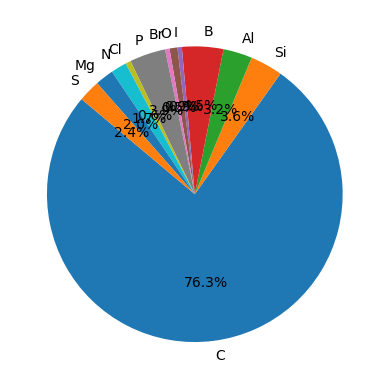

In [18]:
from collections import Counter

